In [1]:
# loading modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import colorcet as cc

In [2]:
# loading dhe data
Brain = pd.read_csv("/content/Birds_includes_whole_brain_numbers_17_09_2024.csv")
# Brain = Brain.drop(['Unnamed: 0'], axis=1)
Brain.head(8)

,Animal,Order,Family,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Namaqua dove,Columbiformes,Columbidae,0.240,0.0870,0.555,"14,167,000","59,533,000","94,490,000",31.850
2,Common ground dove,Columbiformes,Columbidae,0.246,0.0750,0.572,"17,602,000","51,380,000","89,630,000",35.277
3,Diamond dove,Columbiformes,Columbidae,0.240,0.0776,0.545,"18,209,000","54,101,000","87,879,000",39.930
4,King quail,Galliformes,Phasianidae,0.220,0.0717,0.521,"20,523,000","42,945,000","80,478,000",43.810
5,Common quail,Galliformes,Phasianidae,0.360,0.1090,0.787,"22,568,000","75,198,000","117,760,000",94.860
6,Common emerald dove,Columbiformes,Columbidae,0.494,0.1760,1.126,"27,148,000","109,818,000","168,489,000",119.640
7,Common bronzewing,Columbiformes,Columbidae,0.869,0.2570,1.848,"34,077,000","145,208,000","216,703,000",306.025


In [3]:
# Dropping NaN values
Brain = Brain.dropna().reset_index(drop=True)

# Data preparation and feature engineering

In [4]:
# Converting into float and removing commas
if Brain['Forebrain n'].dtype != 'float64':
     Brain['Forebrain n'] = Brain['Forebrain n'].str.replace(',', '').astype(float)
if Brain['Cerebellum n'].dtype != 'float64':
     Brain['Cerebellum n'] = Brain['Cerebellum n'].str.replace(',', '').astype(float)
if Brain['Whole brain n'].dtype != 'float64':
     Brain['Whole brain n'] = Brain['Whole brain n'].str.replace(',', '').astype(float)

In [5]:
Brain['Cerebellum n / Forebrain n'] = Brain['Cerebellum n'] / Brain['Forebrain n']

In [6]:
# Getting relative cortical and cerebellar masses and relative number of neurons in each structure
Brain['Forebrain m r %'] = Brain['Forebrain m']/Brain['Whole brain m']*100
Brain['Cerebellum m r %'] = Brain['Cerebellum m']/Brain['Whole brain m']*100
Brain['Forebrain n r %'] = Brain['Forebrain n']/Brain['Whole brain n']*100
Brain['Cerebellum n r %'] = Brain['Cerebellum n']/Brain['Whole brain n']*100

In [7]:
# Getting neuron densities in a miligram of structure
Brain['Forebrain n d'] = Brain['Forebrain n']/(Brain['Forebrain m']*1000)
Brain['Cerebellum n d'] = Brain['Cerebellum n']/(Brain['Cerebellum m']*1000)
Brain['Whole brain n d'] = Brain['Whole brain n']/(Brain['Whole brain m']*1000)

In [8]:
# Brain mass per body mass
Brain['Forebrain m per body m'] = Brain['Forebrain m']/Brain['Body m']*100
Brain['Cerebellum m per body m'] = Brain['Cerebellum m']/Brain['Body m']*100
Brain['Whole brain m per body m'] = Brain['Whole brain m']/Brain['Body m']*100

In [9]:
# Number of neurons per body mass
Brain['Forebrain n per body m'] = Brain['Forebrain n']/Brain['Body m']
Brain['Cerebellum n per body m'] = Brain['Cerebellum n']/Brain['Body m']
Brain['Whole brain n per body m'] = Brain['Whole brain n']/Brain['Body m']

In [10]:
# Cortex/rest of brain and cerebellum/rest of brain
Brain['Forebrain m/Rest m'] = Brain['Forebrain m']/(Brain['Whole brain m']-Brain['Forebrain m']-Brain['Cerebellum m'])
Brain['Cerebellum m/Rest m'] = Brain['Cerebellum m']/(Brain['Whole brain m']-Brain['Forebrain m']-Brain['Cerebellum m'])
Brain['Forebrain m/Cerebellum m'] = Brain['Forebrain m']/Brain['Cerebellum m']

In [11]:
Breng = Brain
Breng.head()

,Animal,Order,Family,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,...,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
0,Namaqua dove,Columbiformes,Columbidae,0.240,0.0870,0.555,14167000.0,59533000.0,94490000.0,31.850,...,170252.252252,0.753532,0.273155,1.742543,444803.767661,1.869168e+06,2.966719e+06,1.052632,0.381579,2.758621
1,Common ground dove,Columbiformes,Columbidae,0.246,0.0750,0.572,17602000.0,51380000.0,89630000.0,35.277,...,156695.804196,0.697338,0.212603,1.621453,498965.331519,1.456473e+06,2.540749e+06,0.980080,0.298805,3.280000
2,Diamond dove,Columbiformes,Columbidae,0.240,0.0776,0.545,18209000.0,54101000.0,87879000.0,39.930,...,161245.871560,0.601052,0.194340,1.364889,456023.040321,1.354896e+06,2.200826e+06,1.055409,0.341249,3.092784
3,King quail,Galliformes,Phasianidae,0.220,0.0717,0.521,20523000.0,42945000.0,80478000.0,43.810,...,154468.330134,0.502168,0.163661,1.189226,468454.690710,9.802556e+05,1.836978e+06,0.959442,0.312691,3.068340
4,Common quail,Galliformes,Phasianidae,0.360,0.1090,0.787,22568000.0,75198000.0,117760000.0,94.860,...,149631.512071,0.379507,0.114906,0.829644,237908.496732,7.927261e+05,1.241408e+06,1.132075,0.342767,3.302752


In [12]:
pd.set_option('display.max_columns', None)
Breng.describe()

,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Cerebellum n / Forebrain n,Forebrain m r %,Cerebellum m r %,Forebrain n r %,Cerebellum n r %,Forebrain n d,Cerebellum n d,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
count,129.000000,129.000000,129.000000,1.290000e+02,1.290000e+02,1.290000e+02,129.000000,129.000000,129.000000,129.000000,129.000000,129.000000,129.000000,1.290000e+02,129.000000,129.000000,129.000000,129.000000,1.290000e+02,1.290000e+02,1.290000e+02,129.000000,129.000000,129.000000
mean,3.341624,0.620022,5.404403,3.109492e+08,2.830096e+08,6.706423e+08,2245.798372,1.600420,57.473101,12.076602,38.714025,48.353096,104826.714049,5.830571e+05,151442.134835,0.907357,0.170312,1.531883,1.345418e+06,1.249927e+06,3.014664e+06,2.052220,0.401996,5.237388
std,3.704900,0.708397,5.571436,3.641944e+08,1.993004e+08,5.666749e+08,11382.286756,0.990252,8.703180,2.862982,15.178873,13.658651,64014.899952,2.217501e+05,65757.927366,0.810024,0.143063,1.310301,1.762208e+06,1.604332e+06,3.860640e+06,0.803986,0.081057,2.180304
min,0.176000,0.040000,0.357000,1.416700e+07,4.294500e+07,8.047800e+07,5.600000,0.229068,42.226488,6.005789,14.993121,17.521696,18741.594996,1.826565e+05,40473.055231,0.021308,0.004832,0.033527,3.993419e+03,8.826089e+03,1.356935e+04,0.959442,0.243735,2.107527
25%,0.880000,0.221000,1.840000,7.200000e+07,1.331080e+08,2.582170e+08,113.120000,0.798658,49.708405,10.000000,26.355973,38.895588,55043.333333,4.309113e+05,100815.580618,0.281643,0.070719,0.570324,1.521225e+05,3.058448e+05,5.523477e+05,1.334066,0.346154,3.565913
50%,2.240000,0.450000,3.763000,1.497090e+08,2.203140e+08,4.795240e+08,368.600000,1.411272,58.292232,12.731196,36.559765,51.238230,81286.675639,5.408321e+05,139925.299095,0.568720,0.118996,1.039193,4.691055e+05,6.421288e+05,1.354102e+06,1.986911,0.388389,4.409661
75%,4.120000,0.825000,7.076000,3.988990e+08,4.034100e+08,9.178760e+08,867.500000,2.207052,63.301191,14.031303,48.755760,59.835975,143073.556640,6.965390e+05,182342.884662,1.357895,0.221154,2.234902,2.063808e+06,1.524390e+06,3.996251e+06,2.453540,0.431405,6.262136
max,25.580000,5.800900,40.249000,1.916000e+09,1.059572e+09,3.136000e+09,120050.000000,4.444149,76.332637,20.620843,76.491228,72.386671,363636.363636,1.650000e+06,459030.812325,3.288690,0.714286,6.375000,1.142857e+07,1.178571e+07,2.926321e+07,4.616582,0.654131,11.547791


In [13]:
Breng.shape

(129, 27)

In [14]:
pd.set_option('display.max_rows', 170, 'display.max_columns', 50)
Breng.head(170)

,Animal,Order,Family,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,Body m,Cerebellum n / Forebrain n,Forebrain m r %,Cerebellum m r %,Forebrain n r %,Cerebellum n r %,Forebrain n d,Cerebellum n d,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
0,Namaqua dove,Columbiformes,Columbidae,0.24000,0.0870,0.555,1.416700e+07,5.953300e+07,9.449000e+07,31.850,4.202231,43.243243,15.675676,14.993121,63.004551,59029.166667,6.842874e+05,170252.252252,0.753532,0.273155,1.742543,4.448038e+05,1.869168e+06,2.966719e+06,1.052632,0.381579,2.758621
1,Common ground dove,Columbiformes,Columbidae,0.24600,0.0750,0.572,1.760200e+07,5.138000e+07,8.963000e+07,35.277,2.918986,43.006993,13.111888,19.638514,57.324557,71552.845528,6.850667e+05,156695.804196,0.697338,0.212603,1.621453,4.989653e+05,1.456473e+06,2.540749e+06,0.980080,0.298805,3.280000
2,Diamond dove,Columbiformes,Columbidae,0.24000,0.0776,0.545,1.820900e+07,5.410100e+07,8.787900e+07,39.930,2.971113,44.036697,14.238532,20.720536,61.563058,75870.833333,6.971778e+05,161245.871560,0.601052,0.194340,1.364889,4.560230e+05,1.354896e+06,2.200826e+06,1.055409,0.341249,3.092784
3,King quail,Galliformes,Phasianidae,0.22000,0.0717,0.521,2.052300e+07,4.294500e+07,8.047800e+07,43.810,2.092530,42.226488,13.761996,25.501379,53.362410,93286.363636,5.989540e+05,154468.330134,0.502168,0.163661,1.189226,4.684547e+05,9.802556e+05,1.836978e+06,0.959442,0.312691,3.068340
4,Common quail,Galliformes,Phasianidae,0.36000,0.1090,0.787,2.256800e+07,7.519800e+07,1.177600e+08,94.860,3.332063,45.743329,13.850064,19.164402,63.856997,62688.888889,6.898899e+05,149631.512071,0.379507,0.114906,0.829644,2.379085e+05,7.927261e+05,1.241408e+06,1.132075,0.342767,3.302752
5,Common emerald dove,Columbiformes,Columbidae,0.49400,0.1760,1.126,2.714800e+07,1.098180e+08,1.684890e+08,119.640,4.045160,43.872114,15.630551,16.112625,65.178142,54955.465587,6.239659e+05,149634.991119,0.412905,0.147108,0.941157,2.269141e+05,9.179037e+05,1.408300e+06,1.083333,0.385965,2.806818
6,Common bronzewing,Columbiformes,Columbidae,0.86900,0.2570,1.848,3.407700e+07,1.452080e+08,2.167030e+08,306.025,4.261173,47.023810,13.906926,15.725209,67.007840,39214.039125,5.650117e+05,117263.528139,0.283964,0.083980,0.603872,1.113536e+05,4.744972e+05,7.081219e+05,1.203601,0.355956,3.381323
7,Pink-necked green pigeon,Columbiformes,Columbidae,0.64500,0.2000,1.339,3.435700e+07,1.147920e+08,1.744760e+08,128.850,3.341153,48.170276,14.936520,19.691534,65.792430,53266.666667,5.739600e+05,130303.211352,0.500582,0.155219,1.039193,2.666434e+05,8.908964e+05,1.354102e+06,1.305668,0.404858,3.225000
8,Grey partridge,Galliformes,Phasianidae,0.74000,0.2071,1.565,3.688200e+07,1.075460e+08,1.702870e+08,337.330,2.915948,47.284345,13.233227,21.658729,63.155731,49840.540541,5.192950e+05,108809.584665,0.219370,0.061394,0.463937,1.093351e+05,3.188154e+05,5.048083e+05,1.197605,0.335168,3.573153
9,Yellow-rumped tinkerbird,Piciformes,Lybiidae,0.22470,0.0700,0.470,3.792500e+07,6.283000e+07,1.180300e+08,11.200,1.656691,47.808511,14.893617,32.131661,53.232229,168780.596351,8.975714e+05,251127.659574,2.006250,0.625000,4.196429,3.386161e+06,5.609821e+06,1.053839e+07,1.281803,0.399315,3.210000


# Data visualization

In [15]:
X00_forebrain_mass = Breng['Forebrain m']
Y00_forebrain_neurons = Breng["Forebrain n"]
X01_cerebellum_mass = Breng['Cerebellum m']
Y01_cerebellum_neurons = Breng["Cerebellum n"]
x05_forebrain_neuron_density = Breng['Forebrain n d']
y05_cerebellum_neuron_density = Breng['Cerebellum n d']

In [16]:
sns.set("paper", rc={"figure.figsize": (12, 8)})

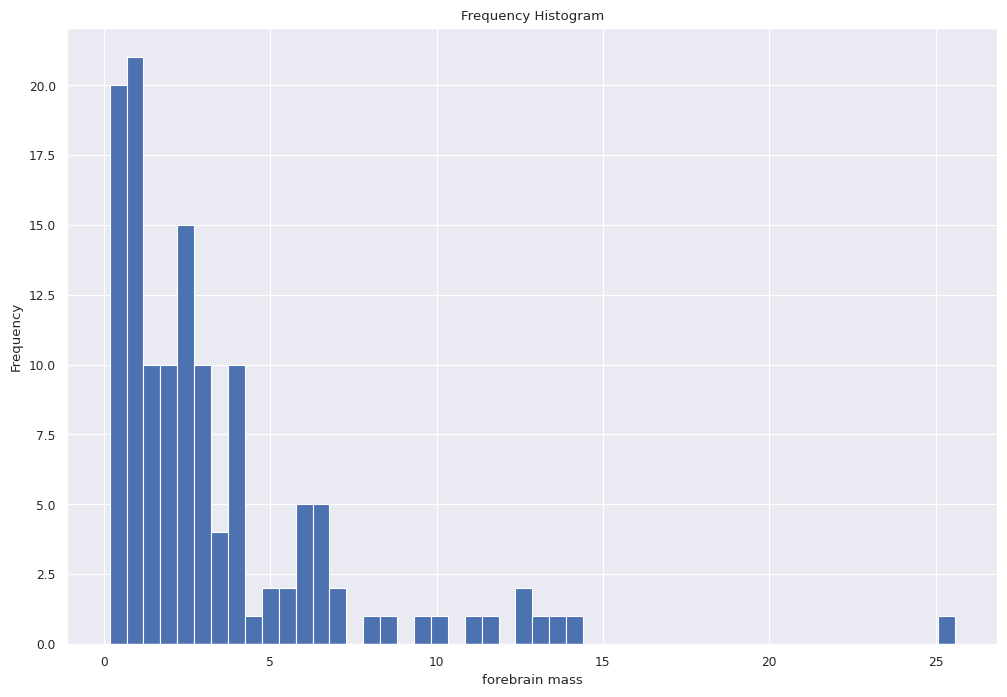

In [17]:
plt.hist(X00_forebrain_mass, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='forebrain mass',ylabel='Frequency')
plt.show()

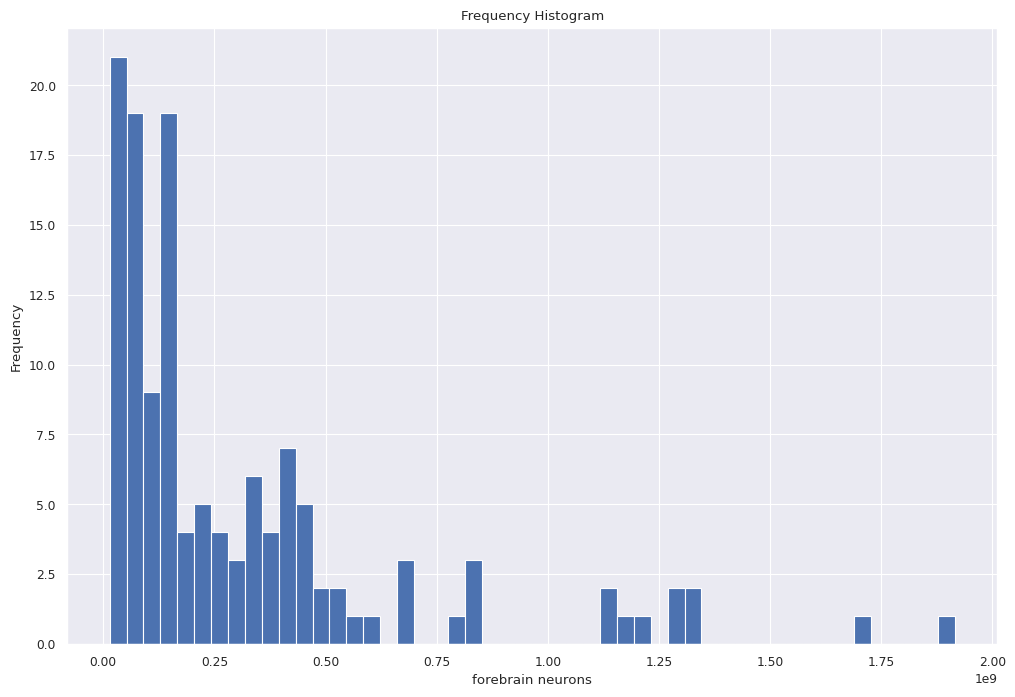

In [18]:
plt.hist(Y00_forebrain_neurons, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='forebrain neurons' ,ylabel='Frequency')
plt.show()

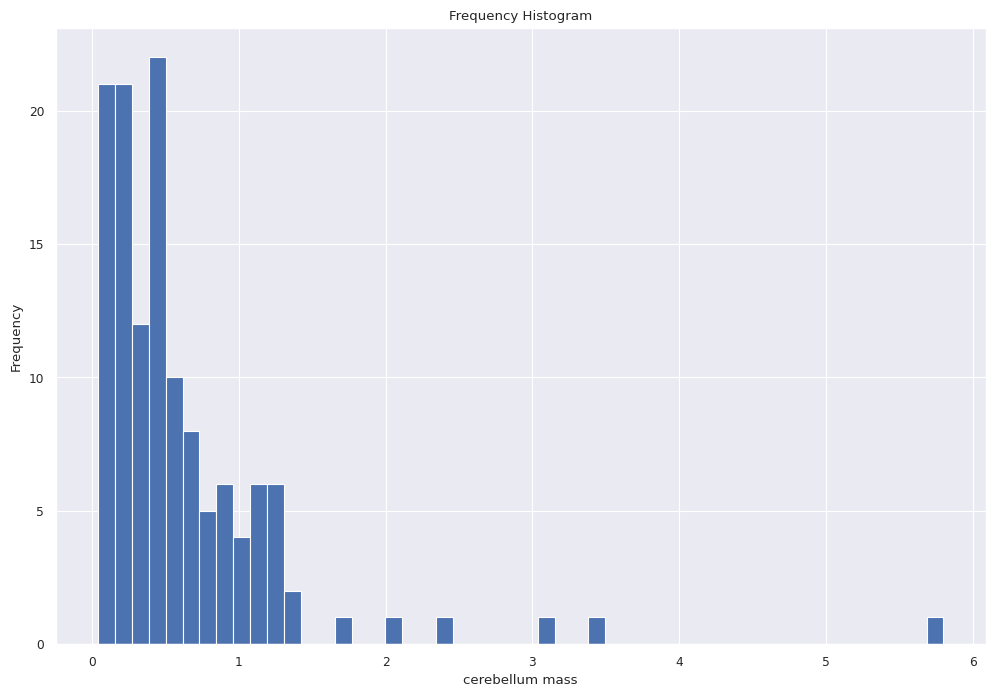

In [19]:
plt.hist(X01_cerebellum_mass, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='cerebellum mass',ylabel='Frequency')
plt.show()

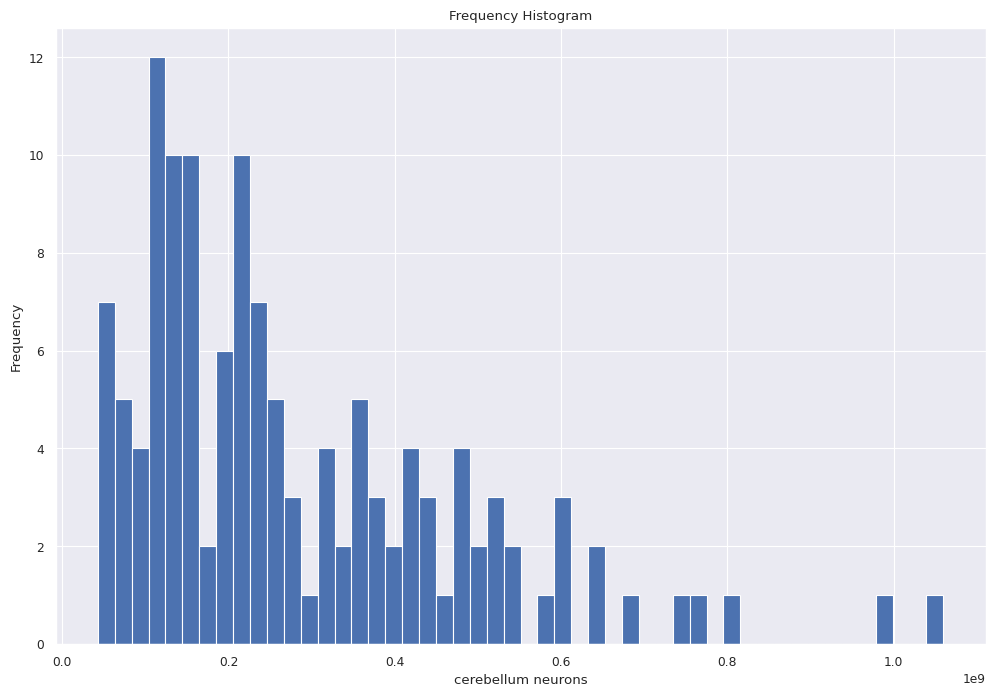

In [20]:
plt.hist(Y01_cerebellum_neurons, bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='cerebellum neurons', ylabel='Frequency')
plt.show()

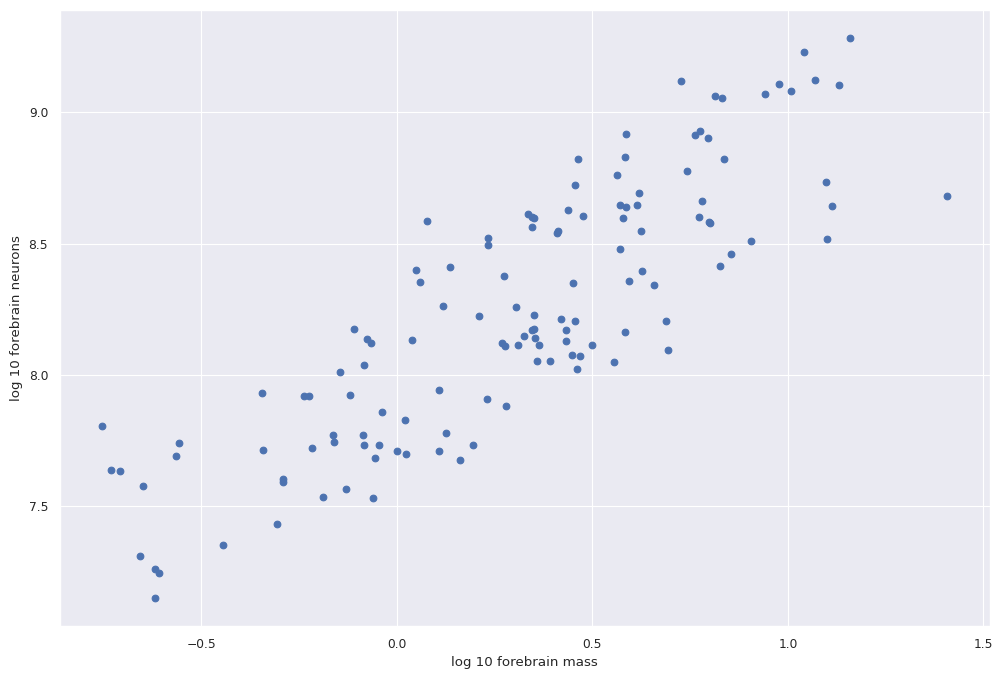

In [21]:
plt.scatter(np.log10(X00_forebrain_mass), np.log10(Y00_forebrain_neurons))
plt.xlabel('log 10 forebrain mass')
plt.ylabel('log 10 forebrain neurons')
plt.show()

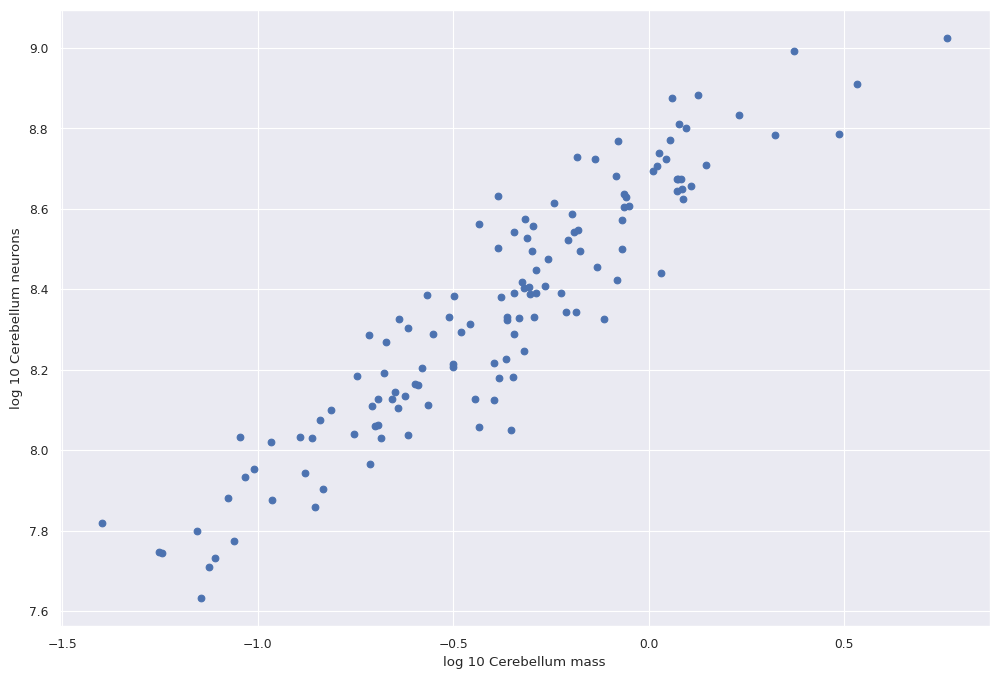

In [22]:
plt.scatter(np.log10(X01_cerebellum_mass), np.log10(Y01_cerebellum_neurons))
plt.xlabel('log 10 Cerebellum mass')
plt.ylabel('log 10 Cerebellum neurons')
plt.show()

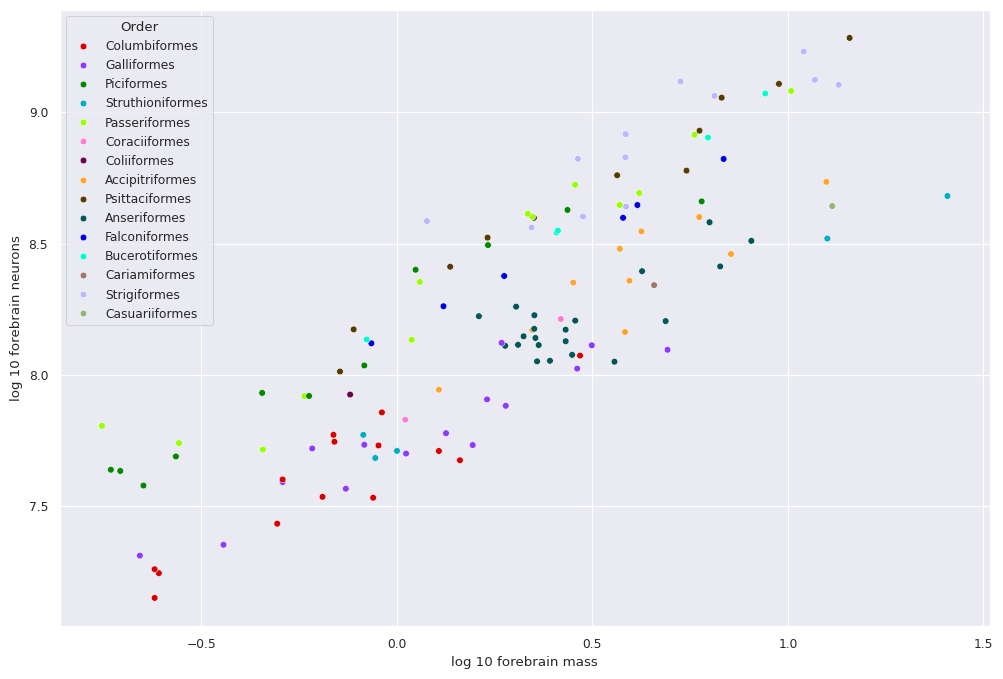

In [23]:
palette = sns.color_palette(cc.glasbey, n_colors=15)
ax = sns.scatterplot(data=Breng, x=np.log10(X00_forebrain_mass), y=np.log10(Y00_forebrain_neurons), hue='Order', palette=palette)
ax.set(xlabel="log 10 forebrain mass", ylabel="log 10 forebrain neurons")
plt.show()

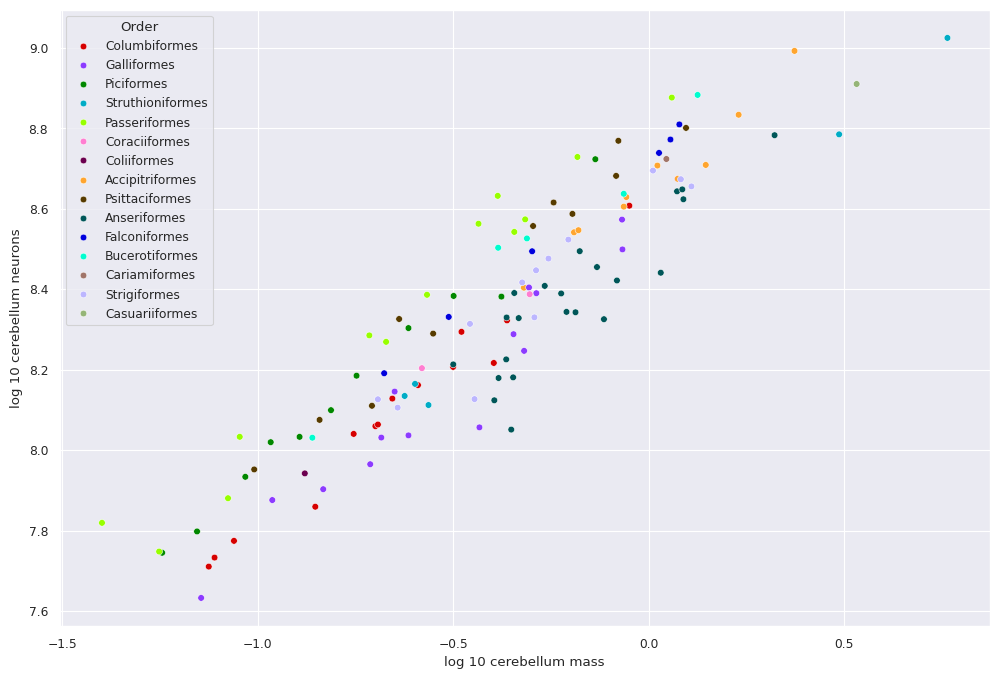

In [24]:
ax_2 = sns.scatterplot(data=Breng, x=np.log10(X01_cerebellum_mass), y=np.log10(Y01_cerebellum_neurons), hue='Order', palette=palette)
ax_2.set(xlabel="log 10 cerebellum mass", ylabel="log 10 cerebellum neurons")
plt.show()

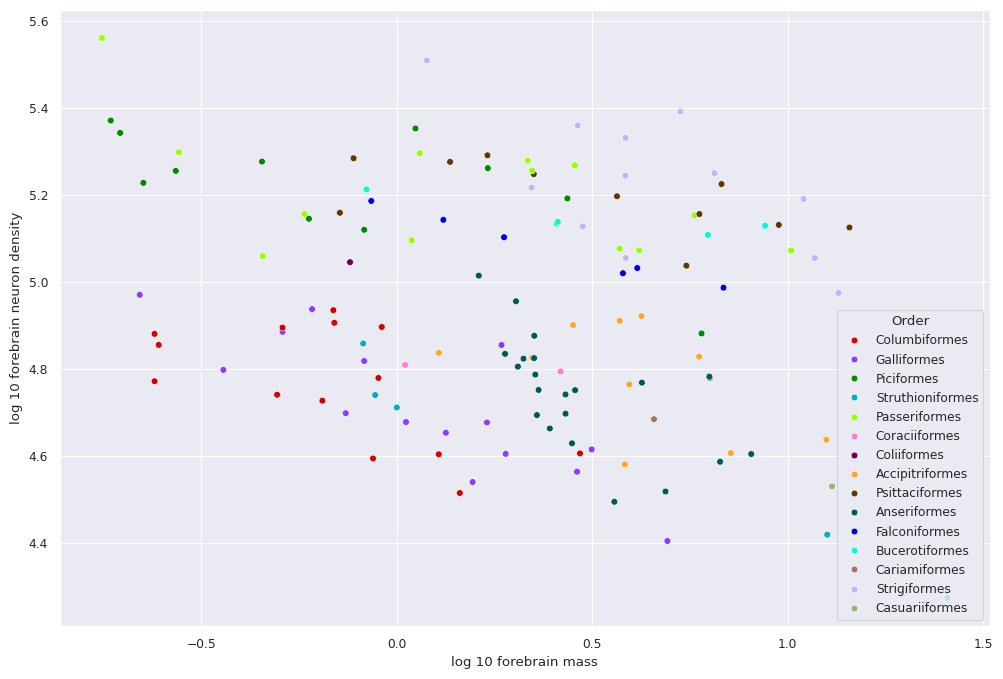

In [25]:
ax_3 = sns.scatterplot(data=Breng, x=np.log10(X00_forebrain_mass), y=np.log10(x05_forebrain_neuron_density), hue='Order', palette=palette)
ax_3.set(xlabel="log 10 forebrain mass", ylabel="log 10 forebrain neuron density")
plt.show()

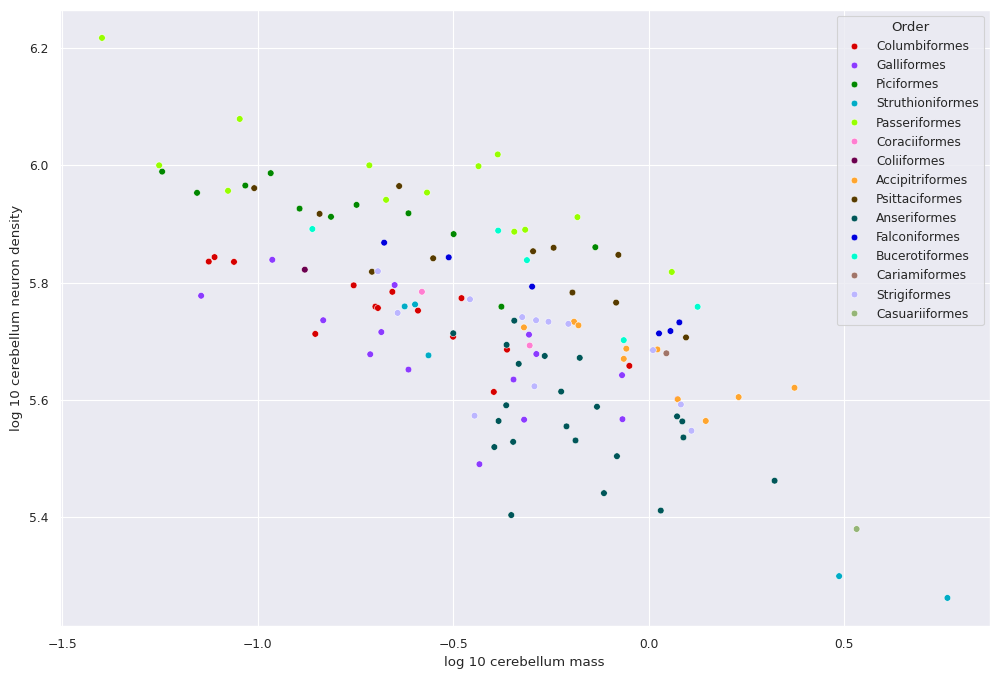

In [26]:
ax_4 = sns.scatterplot(data=Breng, x=np.log10(X01_cerebellum_mass), y=np.log10(y05_cerebellum_neuron_density), hue='Order', palette=palette)
ax_4.set(xlabel="log 10 cerebellum mass", ylabel="log 10 cerebellum neuron density")
plt.show()

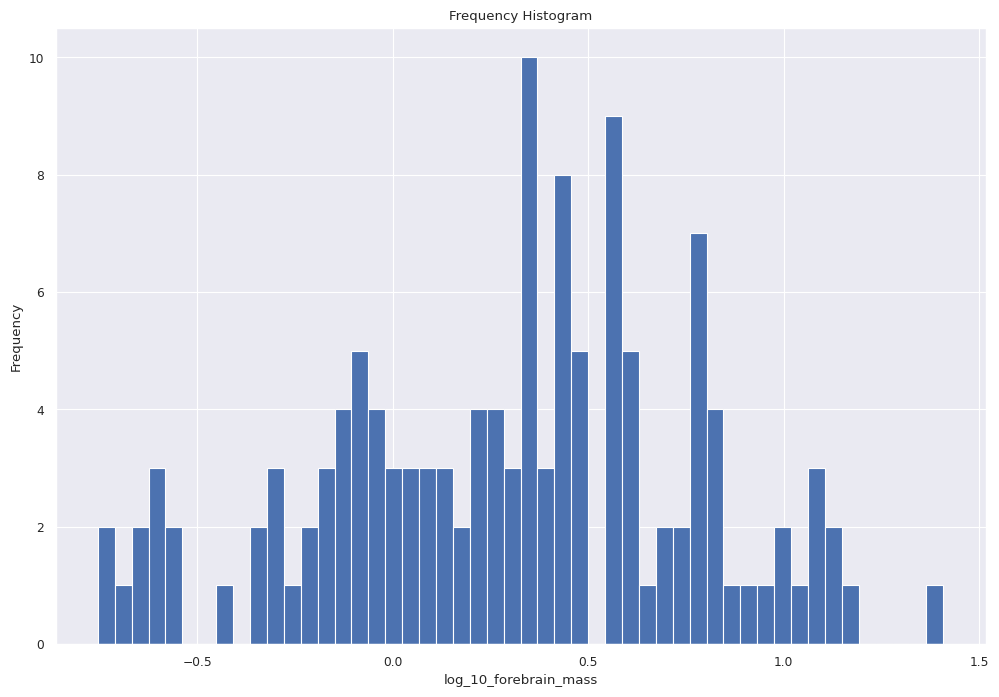

In [27]:
plt.hist(np.log10(X00_forebrain_mass), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_forebrain_mass', ylabel='Frequency')
plt.show()

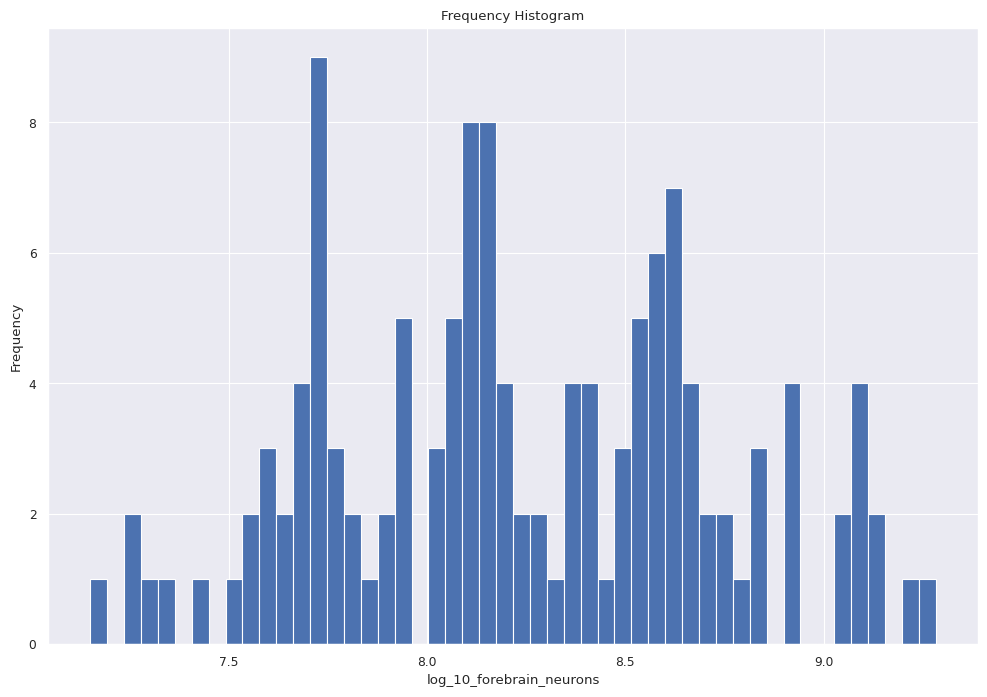

In [28]:
plt.hist(np.log10(Y00_forebrain_neurons), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_forebrain_neurons', ylabel='Frequency')
plt.show()

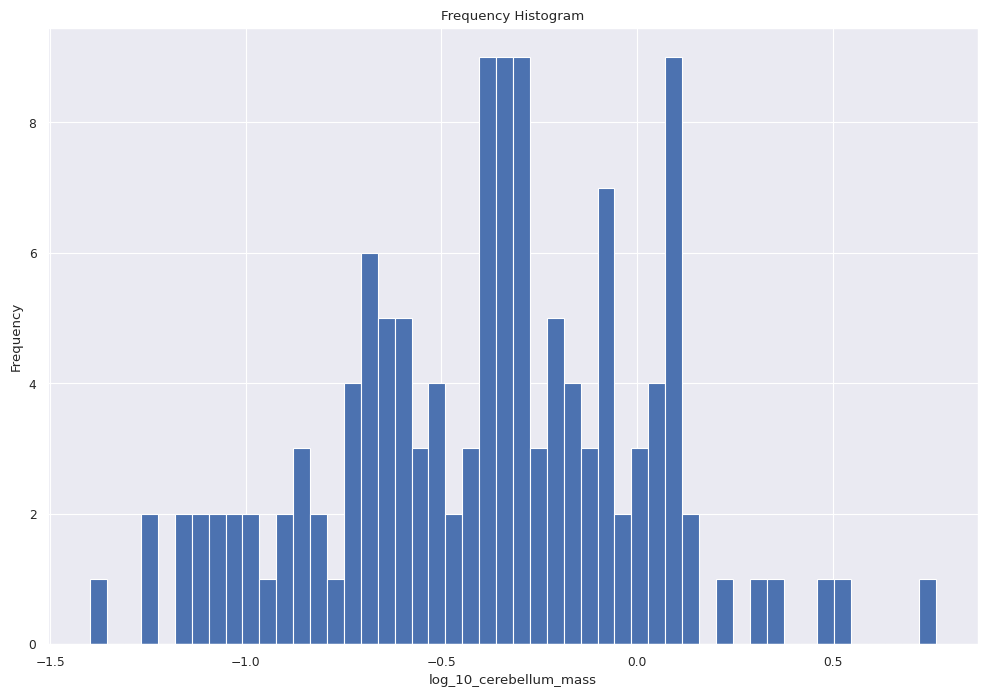

In [29]:
plt.hist(np.log10(X01_cerebellum_mass), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_cerebellum_mass', ylabel='Frequency')
plt.show()

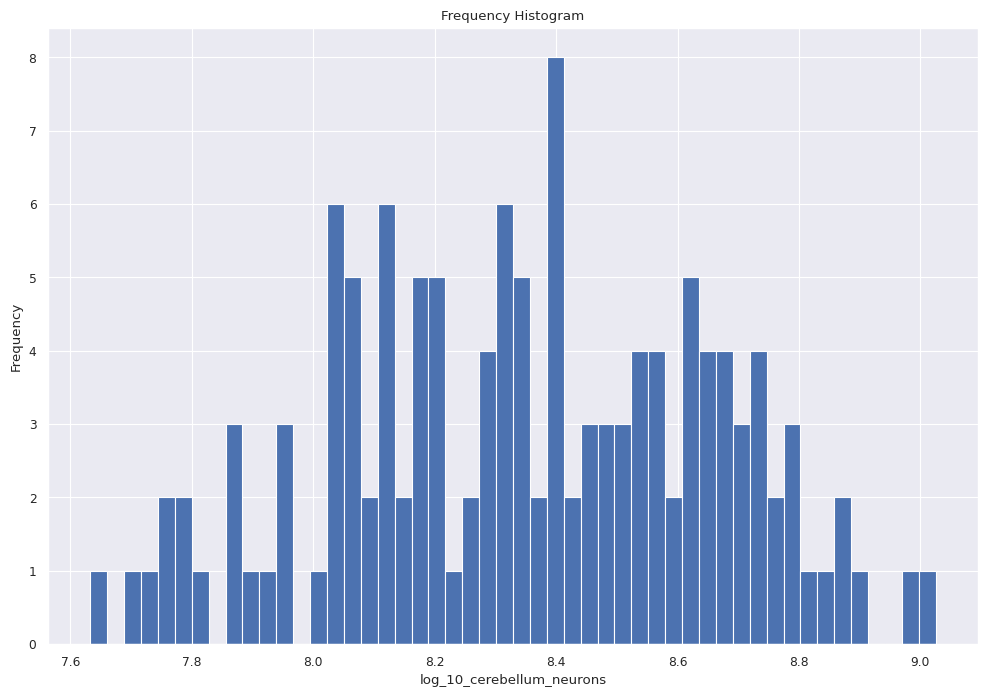

In [30]:
plt.hist(np.log10(Y01_cerebellum_neurons), bins=50)
plt.gca().set(title='Frequency Histogram',xlabel='log_10_cerebellum_neurons', ylabel='Frequency')
plt.show()

In [31]:
# Saving modified data
Breng.to_csv('/content/birds_with_feature_engineering_17_09_2024.csv')

<Axes: xlabel='Order', ylabel='Count'>

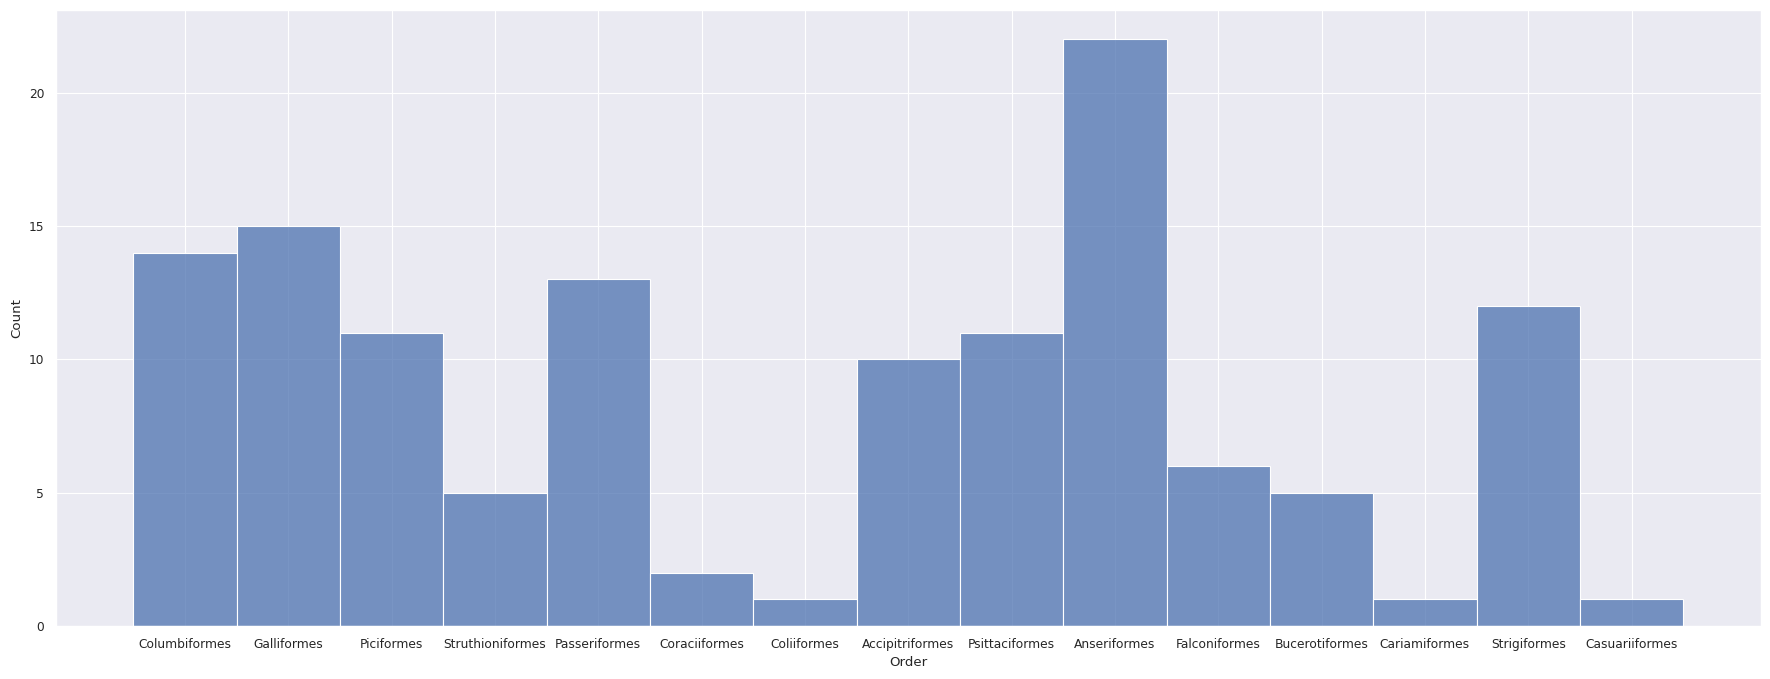

In [32]:
sns.set("paper", rc={"figure.figsize": (22, 8)})
sns.histplot(data=Breng, x="Order")

In [33]:
matrix = Breng.corr(numeric_only=True)

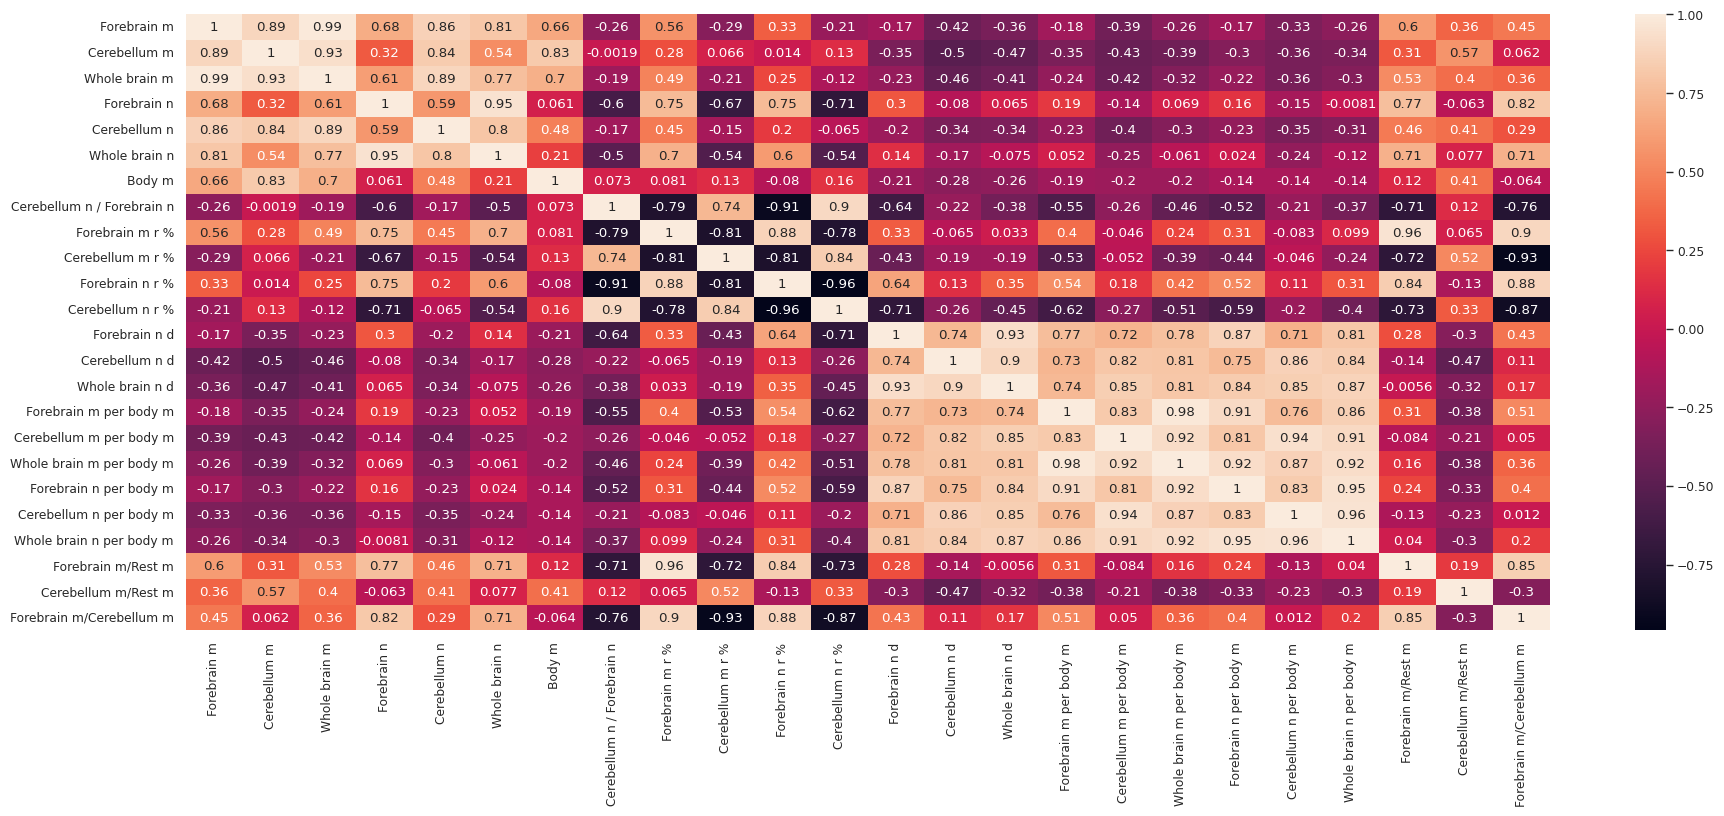

In [34]:
sns.heatmap(matrix, annot=True);

In [35]:
for i in range(3, len(Breng.columns)):
  ratio = max(Breng.iloc[:,i])/min(Breng.iloc[:,i])
  print(Breng.columns[i], 'ratio = ', ratio)

Forebrain m ratio =  145.3409090909091
Cerebellum m ratio =  145.0225
Whole brain m ratio =  112.74229691876752
Forebrain n ratio =  135.2438766146679
Cerebellum n ratio =  24.67276749330539
Whole brain n ratio =  38.96717115236462
Body m ratio =  21437.5
Cerebellum n / Forebrain n ratio =  19.40099806429369
Forebrain m r % ratio =  1.8076956411716325
Cerebellum m r % ratio =  3.433494510191542
Forebrain n r % ratio =  5.1017548813092946
Cerebellum n r % ratio =  4.131259412614042
Forebrain n d ratio =  19.402636953376405
Cerebellum n d ratio =  9.033350258406225
Whole brain n d ratio =  11.341639757683307
Forebrain m per body m ratio =  154.34217813395884
Cerebellum m per body m ratio =  147.8218897067696
Whole brain m per body m ratio =  190.14602847275705
Forebrain n per body m ratio =  2861.851025218498
Cerebellum n per body m ratio =  1335.326905580744
Whole brain n per body m ratio =  2156.5677562922037
Forebrain m/Rest m ratio =  4.811738024181207
Cerebellum m/Rest m ratio =  2.

# Regression

## Regression with many numerical features, some of which are correlated with each other

In [36]:
X = Breng[["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
           "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m", "Order", "Family"]]
# X = Breng[["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
#            "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m"]]
# X = Breng[["Forebrain m", "Cerebellum m", "Body m"]]

Y1 = Breng["Forebrain n"]
Y2 = Breng["Cerebellum n"]
Y3 = Breng["Whole brain n"]

In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [38]:
x_train, x_test, y1_train, y1_test, y2_train, y2_test = train_test_split(X, Y1, Y2, test_size=0.25, random_state=42)

In [39]:
regr_forebrain = RandomForestRegressor(random_state=42)


In [40]:
regr_forebrain.fit(x_train.iloc[:, :-5], y1_train)
# regr_forebrain.fit(x_train, y1_train)

RandomForestRegressor(random_state=42)

In [41]:
mse_y1 = mean_squared_error(y1_test, regr_forebrain.predict(x_test.iloc[:, :-5]))
# mse_y1 = mean_squared_error(y1_test, regr_forebrain.predict(x_test))
print(mse_y1)

1.4896383765535572e+16


In [42]:
r2_y1 = r2_score(y1_test, regr_forebrain.predict(x_test.iloc[:, :-5]))
# r2_y1 = r2_score(y1_test, regr_forebrain.predict(x_test))
print(r2_y1)

0.8972242605944805


In [43]:
preds_y1 = regr_forebrain.predict(x_test.iloc[:, :-5])

In [44]:
# cols = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
#          "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m"]

cols = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
          "Cerebellum m per body m", "Whole brain m per body m"]

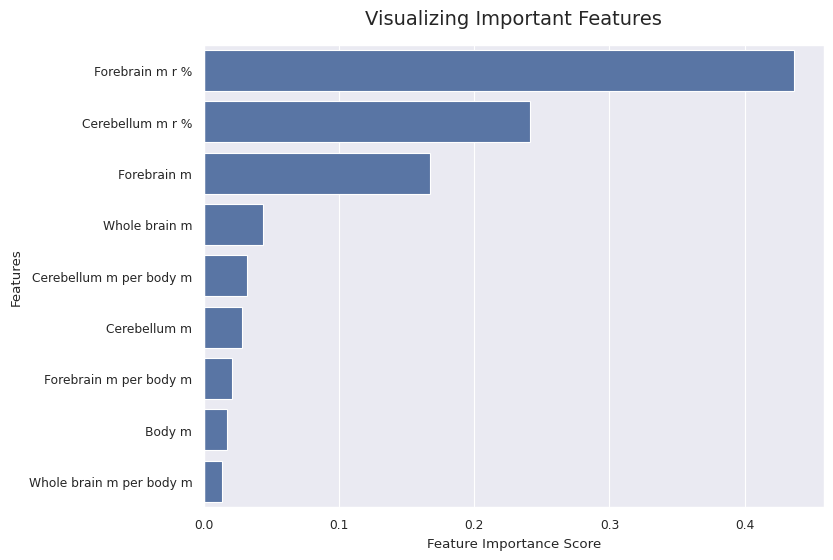

In [45]:
fig01 = plt.figure(figsize=(8, 6))

feature_imp = pd.Series(regr_forebrain.feature_importances_, index=cols).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features", pad=15, size=14)
plt.savefig('Barplot.png')

In [46]:
regr_cerebellum = RandomForestRegressor(random_state=42)

In [47]:
regr_cerebellum.fit(x_train.iloc[:, :-5], y2_train)

RandomForestRegressor(random_state=42)

In [48]:
mse_y2 = mean_squared_error(y2_test, regr_cerebellum.predict(x_test.iloc[:, :-5]))
print(mse_y2)

2881814202125051.5


In [49]:
r2_y2 = r2_score(y2_test, regr_cerebellum.predict(x_test.iloc[:, :-5]))
print(r2_y2)

0.9088235858287304


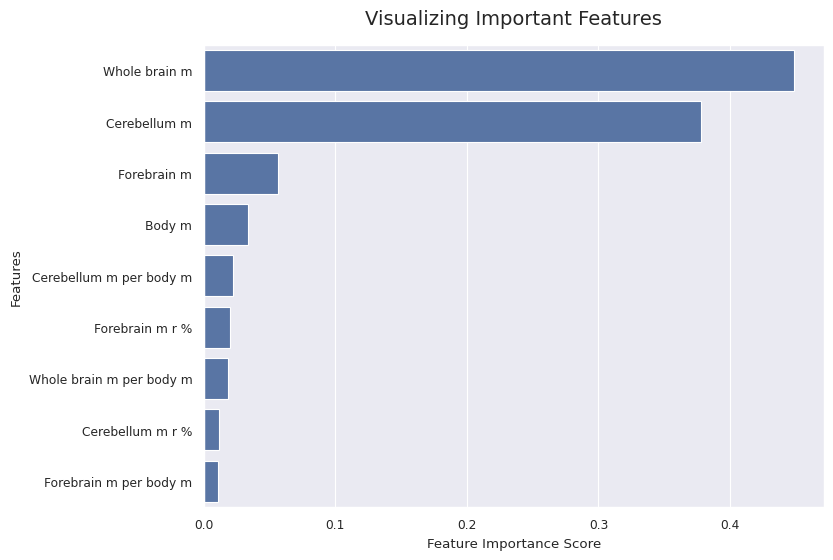

In [50]:
fig01 = plt.figure(figsize=(8, 6))

feature_imp = pd.Series(regr_cerebellum.feature_importances_, index=cols).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features", pad=15, size=14)
plt.savefig('Barplot.png')

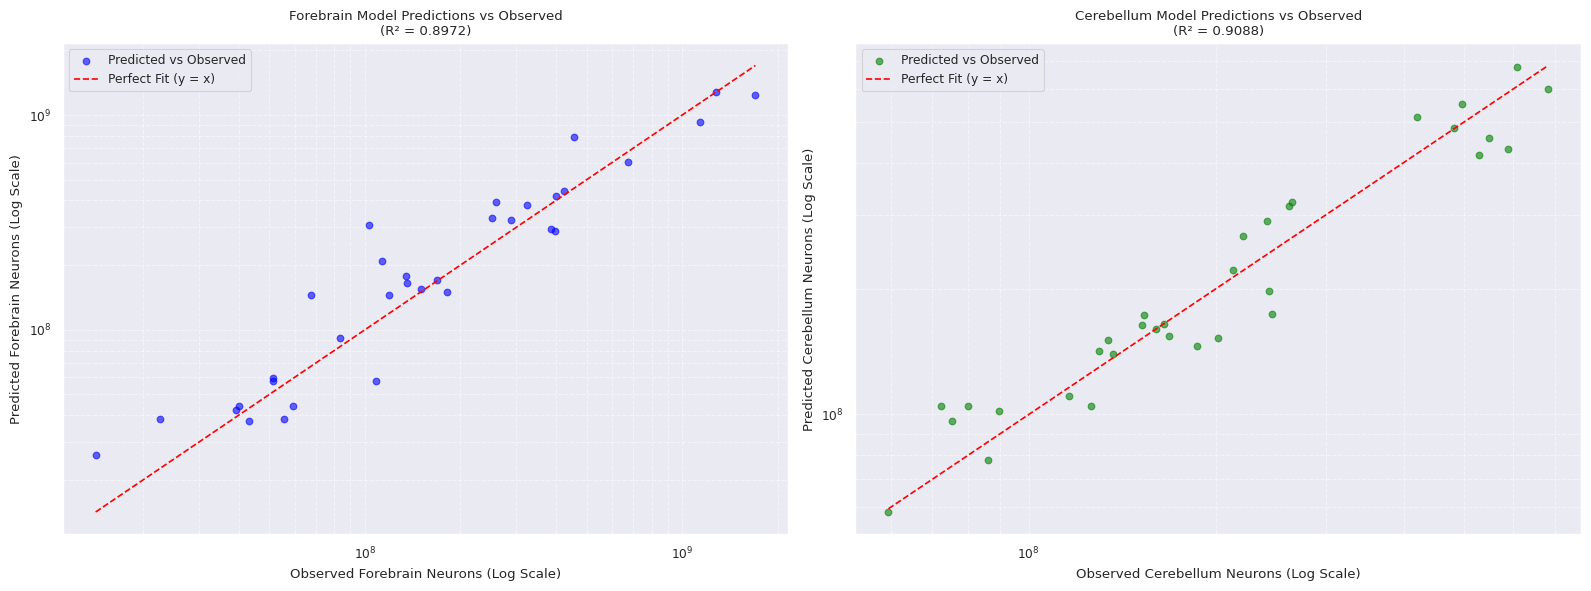

In [51]:
import matplotlib.pyplot as plt
import numpy as np

preds_y2 = regr_cerebellum.predict(x_test.iloc[:, :-5])

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Forebrain Plot
axes[0].scatter(y1_test, preds_y1, color='blue', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y1 = np.linspace(min(y1_test), max(y1_test), 100)
axes[0].plot(ideal_y1, ideal_y1, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Observed Forebrain Neurons (Log Scale)')
axes[0].set_ylabel('Predicted Forebrain Neurons (Log Scale)')
axes[0].set_title(f'Forebrain Model Predictions vs Observed\n(R² = {r2_y1:.4f})')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# 2. Cerebellum Plot
axes[1].scatter(y2_test, preds_y2, color='green', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y2 = np.linspace(min(y2_test), max(y2_test), 100)
axes[1].plot(ideal_y2, ideal_y2, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Observed Cerebellum Neurons (Log Scale)')
axes[1].set_ylabel('Predicted Cerebellum Neurons (Log Scale)')
axes[1].set_title(f'Cerebellum Model Predictions vs Observed\n(R² = {r2_y2:.4f})')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Regression with each individual feature

In [52]:
for i in range(x_train.shape[1]-2):
    train_feature = x_train.iloc[:,i]
    test_feature = x_test.iloc[:,i]
    regr_forebrain_one = RandomForestRegressor(random_state=42)
    regr_forebrain_one.fit(train_feature.values.reshape(-1,1), y1_train)
    print(x_train.columns[i], 'MSE = ', mean_squared_error(y1_test, regr_forebrain_one.predict(test_feature.values.reshape(-1,1))))
    print(x_train.columns[i], 'r2 = ', r2_score(y1_test, regr_forebrain_one.predict(test_feature.values.reshape(-1,1))))

Forebrain m MSE =  5.229680122938399e+16
Forebrain m r2 =  0.6391847511790941
Cerebellum m MSE =  1.7772199454943373e+17
Cerebellum m r2 =  -0.2261707059871152
Whole brain m MSE =  7.85595929360067e+16
Whole brain m r2 =  0.45798789971598
Body m MSE =  1.067138244946684e+17
Body m r2 =  0.26374129521252554
Forebrain m r % MSE =  2.6450613461454836e+16
Forebrain m r % r2 =  0.8175072957961707
Cerebellum m r % MSE =  5.2359694331675176e+16
Cerebellum m r % r2 =  0.6387508280744518
Forebrain m per body m MSE =  1.1732062885396542e+17
Forebrain m per body m r2 =  0.1905609732018536
Cerebellum m per body m MSE =  2.5969438723801635e+17
Cerebellum m per body m r2 =  -0.791728991945102
Whole brain m per body m MSE =  1.3010794499249626e+17
Whole brain m per body m r2 =  0.10233648249087679
Forebrain m/Rest m MSE =  7.750906564335629e+16
Forebrain m/Rest m r2 =  0.465235881573001
Cerebellum m/Rest m MSE =  1.7145595298426435e+17
Cerebellum m/Rest m r2 =  -0.18293893476382306
Forebrain m/Cerebe

In [53]:
for i in range(x_train.shape[1]-2):
    train_feature = x_train.iloc[:,i]
    test_feature = x_test.iloc[:,i]
    regr_cerebellum_one = RandomForestRegressor(random_state=42)
    regr_cerebellum_one.fit(train_feature.values.reshape(-1,1), y2_train)
    print(x_train.columns[i], 'MSE = ', mean_squared_error(y2_test, regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))))
    print(x_train.columns[i], 'r2 = ', r2_score(y2_test, regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))))

#    preds_y2 = regr_cerebellum_one.predict(test_feature.values.reshape(-1,1))



Forebrain m MSE =  6813011806948903.0
Forebrain m r2 =  0.784446205516629
Cerebellum m MSE =  8309017199684830.0
Cerebellum m r2 =  0.7371147685385053
Whole brain m MSE =  7322687989879179.0
Whole brain m r2 =  0.7683207916319257
Body m MSE =  1.9820126373428696e+16
Body m r2 =  0.37291999955512
Forebrain m r % MSE =  4.302839837861417e+16
Forebrain m r % r2 =  -0.36135600581118643
Cerebellum m r % MSE =  3.726933211326742e+16
Cerebellum m r % r2 =  -0.17914751691490727
Forebrain m per body m MSE =  3.1039464618349972e+16
Forebrain m per body m r2 =  0.017956438825843635
Cerebellum m per body m MSE =  3.670284926708042e+16
Cerebellum m per body m r2 =  -0.16122482274302774
Whole brain m per body m MSE =  2.7762278402472416e+16
Whole brain m per body m r2 =  0.12164184904933784
Forebrain m/Rest m MSE =  4.1308606055839176e+16
Forebrain m/Rest m r2 =  -0.3069442755218863
Cerebellum m/Rest m MSE =  3.690575585427486e+16
Cerebellum m/Rest m r2 =  -0.16764449234507128
Forebrain m/Cerebellum

## Pairing 1 well performing feature with each of others, including categorical taxonomic features, 'order' and 'family'

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [55]:
cat_cols = ["Order", "Family"]

In [56]:
# 1. Pairwise combinations with 'Forebrain m' (excluding 'Forebrain m' itself)
forebrain_others = [col for col in x_train.columns if col != 'Forebrain m']

print("--- Pairwise combinations with 'Forebrain m' ---\n")
for col_name in forebrain_others:
    features_to_use = ['Forebrain m r %', col_name]

    # Prepare train and test subsets
    train_subset = x_train[features_to_use]
    test_subset = x_test[features_to_use]

    # Determine transformer requirements dynamically
    step_cat_cols = [c for c in [col_name] if c in cat_cols]

    if step_cat_cols:
        OHE_step = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        transformer = ColumnTransformer([('cat_cols', OHE_step, step_cat_cols)], remainder='passthrough')
    else:
        transformer = 'passthrough'

    pipe = Pipeline([
        ("preprocessing", transformer),
        ("classifier", RandomForestRegressor(random_state=42))
    ])

    # Evaluate for Forebrain n (y1)
    pipe.fit(train_subset, y1_train)
    preds_y1 = pipe.predict(test_subset)
    mse_y1 = mean_squared_error(y1_test, preds_y1)
    r2_y1 = r2_score(y1_test, preds_y1)

    print(f"Features: {features_to_use}")
    print(f"  [Forebrain n]   MSE = {mse_y1:.4e} | R2 = {r2_y1:.4f}")
    print("-" * 50)

print("\n" + "="*60 + "\n")

# 2. Pairwise combinations with 'Cerebellum m' (excluding 'Cerebellum m' itself)
cerebellum_others = [col for col in x_train.columns if col != 'Cerebellum m']

print("--- Pairwise combinations with 'Cerebellum m' ---\n")
for col_name in cerebellum_others:
    features_to_use_cerebellum = ['Whole brain m', col_name]

    # Prepare train and test subsets
    train_subset_cerebellum = x_train[features_to_use_cerebellum]
    test_subset_cerebellum = x_test[features_to_use_cerebellum]

    # Determine transformer requirements dynamically
    step_cat_cols = [c for c in [col_name] if c in cat_cols]

    if step_cat_cols:
        OHE_step = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        transformer = ColumnTransformer([('cat_cols', OHE_step, step_cat_cols)], remainder='passthrough')
    else:
        transformer = 'passthrough'

    pipe = Pipeline([
        ("preprocessing", transformer),
        ("classifier", RandomForestRegressor(random_state=42))
    ])

    # Evaluate for Cerebellum n (y2)
    pipe.fit(train_subset_cerebellum, y2_train)
    preds_y2 = pipe.predict(test_subset_cerebellum)
    mse_y2 = mean_squared_error(y2_test, preds_y2)
    r2_y2 = r2_score(y2_test, preds_y2)

    print(f"Features: {features_to_use_cerebellum}")
    print(f"  [Cerebellum n]   MSE = {mse_y2:.4e} | R2 = {r2_y2:.4f}")
    print("-" * 50)


--- Pairwise combinations with 'Forebrain m' ---

Features: ['Forebrain m r %', 'Cerebellum m']
  [Forebrain n]   MSE = 2.8474e+16 | R2 = 0.8035
--------------------------------------------------
Features: ['Forebrain m r %', 'Whole brain m']
  [Forebrain n]   MSE = 2.5623e+16 | R2 = 0.8232
--------------------------------------------------
Features: ['Forebrain m r %', 'Body m']
  [Forebrain n]   MSE = 2.0963e+16 | R2 = 0.8554
--------------------------------------------------
Features: ['Forebrain m r %', 'Forebrain m r %']
  [Forebrain n]   MSE = 2.6451e+16 | R2 = 0.8175
--------------------------------------------------
Features: ['Forebrain m r %', 'Cerebellum m r %']
  [Forebrain n]   MSE = 3.2646e+16 | R2 = 0.7748
--------------------------------------------------
Features: ['Forebrain m r %', 'Forebrain m per body m']
  [Forebrain n]   MSE = 2.1343e+16 | R2 = 0.8527
--------------------------------------------------
Features: ['Forebrain m r %', 'Cerebellum m per body m']
  [Fo

## Using well performing + both taxonomic features

In [57]:
# Features for Forebrain n prediction
features_y1 = ['Forebrain m r %', 'Order', 'Family']
train_subset_y1 = x_train[features_y1]
test_subset_y1 = x_test[features_y1]

# Features for Cerebellum n prediction
features_y2 = ['Whole brain m', 'Order', 'Family']
train_subset_y2 = x_train[features_y2]
test_subset_y2 = x_test[features_y2]

# Transformers
OHE_final = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
transformer = ColumnTransformer([
    ('cat_cols', OHE_final, ['Order', 'Family'])
], remainder='passthrough')

pipe_y1 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

pipe_y2 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

# Evaluate for Forebrain n (y1)
pipe_y1.fit(train_subset_y1, y1_train)
preds_y1 = pipe_y1.predict(test_subset_y1)
mse_y1 = mean_squared_error(y1_test, preds_y1)
r2_y1 = r2_score(y1_test, preds_y1)

# Evaluate for Cerebellum n (y2) using Cerebellum m
pipe_y2.fit(train_subset_y2, y2_train)
preds_y2 = pipe_y2.predict(test_subset_y2)
mse_y2 = mean_squared_error(y2_test, preds_y2)
r2_y2 = r2_score(y2_test, preds_y2)

print(f"Forebrain model features: {features_y1}")
print(f"  [Forebrain n]   MSE = {mse_y1:.4e} | R2 = {r2_y1:.4f}")
print(f"\nCerebellum model features: {features_y2}")
print(f"  [Cerebellum n]  MSE = {mse_y2:.4e} | R2 = {r2_y2:.4f}")

Forebrain model features: ['Forebrain m r %', 'Order', 'Family']
  [Forebrain n]   MSE = 2.6283e+16 | R2 = 0.8187

Cerebellum model features: ['Whole brain m', 'Order', 'Family']
  [Cerebellum n]  MSE = 2.4683e+15 | R2 = 0.9219


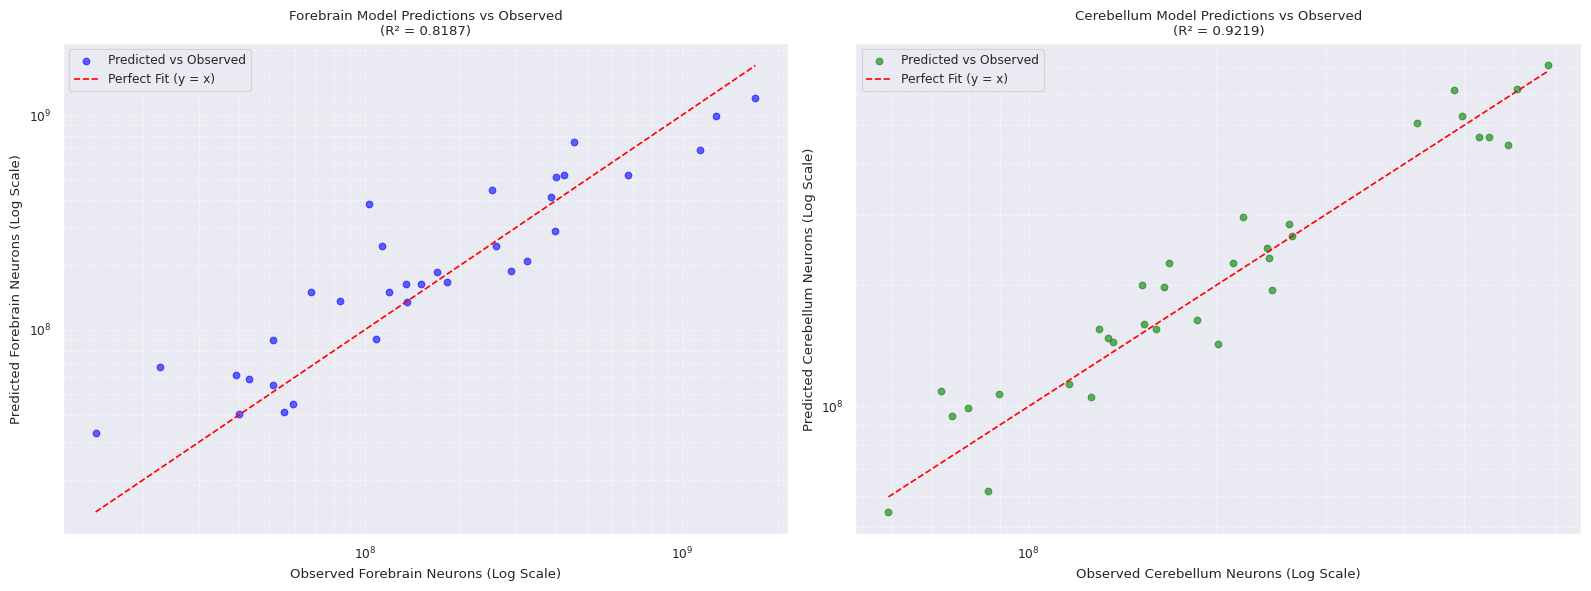

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Forebrain Plot
axes[0].scatter(y1_test, preds_y1, color='blue', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y1 = np.linspace(min(y1_test), max(y1_test), 100)
axes[0].plot(ideal_y1, ideal_y1, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Observed Forebrain Neurons (Log Scale)')
axes[0].set_ylabel('Predicted Forebrain Neurons (Log Scale)')
axes[0].set_title(f'Forebrain Model Predictions vs Observed\n(R² = {r2_y1:.4f})')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# 2. Cerebellum Plot
axes[1].scatter(y2_test, preds_y2, color='green', alpha=0.6, label='Predicted vs Observed')
# Add an identity line (y = x) for comparison
ideal_y2 = np.linspace(min(y2_test), max(y2_test), 100)
axes[1].plot(ideal_y2, ideal_y2, color='red', linestyle='--', label='Perfect Fit (y = x)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Observed Cerebellum Neurons (Log Scale)')
axes[1].set_ylabel('Predicted Cerebellum Neurons (Log Scale)')
axes[1].set_title(f'Cerebellum Model Predictions vs Observed\n(R² = {r2_y2:.4f})')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Using more numerical features with categorical ones

In [59]:
# Features for Forebrain n prediction
# features_y1 = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
#            "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m", "Order", "Family"]

features_y1 = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m", "Forebrain m per body m",
               "Cerebellum m per body m", "Whole brain m per body m", "Order", "Family"]

train_subset_y1 = x_train[features_y1]
test_subset_y1 = x_test[features_y1]

# Features for Cerebellum n prediction
features_y2 = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Forebrain m r %", "Cerebellum m r %", "Forebrain m per body m",
               "Cerebellum m per body m", "Whole brain m per body m", "Forebrain m/Rest m", "Cerebellum m/Rest m", "Forebrain m/Cerebellum m", "Order", "Family"]

# features_y2 = ["Forebrain m", "Cerebellum m", "Whole brain m", "Body m", "Order", "Family"]

train_subset_y2 = x_train[features_y2]
test_subset_y2 = x_test[features_y2]

# Transformers
OHE_final = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
transformer = ColumnTransformer([
    ('cat_cols', OHE_final, ['Order', 'Family'])
], remainder='passthrough')

pipe_y1 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

pipe_y2 = Pipeline([
    ("preprocessing", transformer),
    ("classifier", RandomForestRegressor(random_state=42))
])

# Evaluate for Forebrain n (y1)
pipe_y1.fit(train_subset_y1, y1_train)
preds_y1 = pipe_y1.predict(test_subset_y1)
mse_y1 = mean_squared_error(y1_test, preds_y1)
r2_y1 = r2_score(y1_test, preds_y1)

# Evaluate for Cerebellum n (y2) using Cerebellum m
pipe_y2.fit(train_subset_y2, y2_train)
preds_y2 = pipe_y2.predict(test_subset_y2)
mse_y2 = mean_squared_error(y2_test, preds_y2)
r2_y2 = r2_score(y2_test, preds_y2)

print(f"Forebrain model features: {features_y1}")
print(f"  [Forebrain n]   MSE = {mse_y1:.4e} | R2 = {r2_y1:.4f}")
print(f"\nCerebellum model features: {features_y2}")
print(f"  [Cerebellum n]  MSE = {mse_y2:.4e} | R2 = {r2_y2:.4f}")

Forebrain model features: ['Forebrain m', 'Cerebellum m', 'Whole brain m', 'Body m', 'Forebrain m/Rest m', 'Cerebellum m/Rest m', 'Forebrain m/Cerebellum m', 'Forebrain m per body m', 'Cerebellum m per body m', 'Whole brain m per body m', 'Order', 'Family']
  [Forebrain n]   MSE = 1.5443e+16 | R2 = 0.8935

Cerebellum model features: ['Forebrain m', 'Cerebellum m', 'Whole brain m', 'Body m', 'Forebrain m r %', 'Cerebellum m r %', 'Forebrain m per body m', 'Cerebellum m per body m', 'Whole brain m per body m', 'Forebrain m/Rest m', 'Cerebellum m/Rest m', 'Forebrain m/Cerebellum m', 'Order', 'Family']
  [Cerebellum n]  MSE = 2.5981e+15 | R2 = 0.9178
